<a href="https://colab.research.google.com/github/AHTISHAM327/ai-job-market-skill-miner/blob/ahtisham-m2-baseline/ahtisham/ahtisham_m2_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M2 notebook · Ahtisham · first baseline model
**Question:** can we predict the pay band (low / mid / high) of a data/AI posting from its job-level fields?
This is the baseline that the next models (skill features, tuning) must beat.

**How to run:** Colab → File → Upload notebook → Runtime → Run all → allow Drive. Needs the Drive shortcut of the shared folder in My Drive. About 5 minutes.
Then fill the last cell in your own words, run all once more, and save to GitHub.

**Rules used:** seed 42, no pay column as a feature, encoding inside the Pipeline, stratified 5-fold CV.

*Starter code written with AI help (Claude). The member read it, ran it and wrote the explanations below. Disclosed in the report.*

## 1. Load

In [1]:
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
drive.mount("/content/drive")
SEED = 42
root = next(Path("/content/drive/MyDrive").glob("AI Job Market Skill Miner*"))
raw = root / "data/raw/linkedin_postings_2023_24_v13"
files = {p.name: p for p in raw.rglob("*.csv")}
cols = ["job_id", "title", "company_name", "description", "min_salary", "med_salary", "max_salary",
        "pay_period", "currency", "normalized_salary", "formatted_experience_level",
        "formatted_work_type", "remote_allowed"]
df = pd.read_csv(files["postings.csv"], usecols=cols)
print("postings:", df.shape)

Mounted at /content/drive
postings: (123849, 13)


In [2]:
BG, PANEL, TEXT, GRID = "#1b1d23", "#22252d", "#d6d8de", "#343842"
SOFT = ["#b4a7d6", "#e6b89c", "#a9bfa5", "#d9a5b3", "#d9cfa3", "#9fb3c8", "#c4b5a0", "#b0a8c8"]
MODEL_COLORS = ["#8b8f9a", "#b4a7d6", "#e6b89c"]
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": PANEL, "savefig.facecolor": BG,
                     "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "text.color": TEXT,
                     "xtick.color": TEXT, "ytick.color": TEXT, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})

## 2. Data/AI subset (team's final filter)
**What this shows:** the same subset the whole team uses. The printed counts must match.

In [3]:
INCLUDE = r"data scien|data analy|data engineer|machine learning|\bml\b|\bai\b|artificial intelligence|business intelligence|deep learning|nlp"
EXCLUDE = r"data entry|clerk|content writer|prompt creator|\bsales (?:director|specialist|representative|executive|manager)|pre.?sales|\bit sales|business development|venture"
t = df["title"].fillna("").str.lower()
sub = df[t.str.contains(INCLUDE, regex=True) & ~t.str.contains(EXCLUDE, regex=True)].copy()
has_pay = sub[["min_salary", "med_salary", "max_salary"]].notna().any(axis=1)
got = (len(sub), int(has_pay.sum()), int((sub["formatted_experience_level"] == "Entry level").sum()))
print("data/AI postings | with pay | entry level:", got)
print("team's final filter:                    ", (1753, 579, 281))
if got == (1753, 579, 281):
    print("OK: same subset as the team.")
else:
    print("MISMATCH: take a screenshot, post it in the group, and keep going. Ahtisham decides the fix.")

data/AI postings | with pay | entry level: (1753, 579, 281)
team's final filter:                     (1753, 579, 281)
OK: same subset as the team.


## 3. Pay rule and salary bands
**What this shows:** which rows are kept for the model and where the low / mid / high cut points are.
Bands are equal-frequency (`qcut`), so each has about the same number of rows.

In [4]:
LOW, HIGH = 15_000, 500_000
pay = sub[sub["normalized_salary"].notna()]
usd = pay[pay["currency"].eq("USD")]
data = usd[usd["normalized_salary"].between(LOW, HIGH)].copy()
print("with pay:", len(pay), "| USD:", len(usd), "| inside", f"{LOW:,}-{HIGH:,}:", len(data))

DEDUP = True
key = ["title", "company_name", "description"]
print("repeated title + company + description:", int(data.duplicated(key).sum()))
if DEDUP:
    data = data.drop_duplicates(key)
print("rows used for the model:", len(data))

with pay: 579 | USD: 579 | inside 15,000-500,000: 574
repeated title + company + description: 22
rows used for the model: 552


In [5]:
data["band"] = pd.qcut(data["normalized_salary"], 3, labels=["low", "mid", "high"])
bands = data.groupby("band", observed=True)["normalized_salary"].agg(rows="count", min="min", max="max").round(0)
display(bands)
if bands["rows"].min() < 100:
    print("WARNING: a band has fewer than 100 rows. Tell the group and widen the filter with Rija.")

,rows,min,max
band,,,
low,184,35000.0,119600.0
mid,184,120000.0,165450.0
high,184,166000.0,500000.0


## 4. Features
**What this shows:** the only inputs the model sees. No pay column is used (leakage).
Empty `remote_allowed` is treated as "not remote" (same assumption as the M1 test).

In [6]:
X = pd.DataFrame({
    "experience": data["formatted_experience_level"].astype("object"),
    "work_type": data["formatted_work_type"].astype("object"),
    "remote": np.where(data["remote_allowed"].fillna(0).astype(float).eq(1), "remote", "not_remote_or_empty"),
}, index=data.index)
y = data["band"].astype(str)
assert not {"min_salary", "med_salary", "max_salary", "normalized_salary", "pay_period", "currency"} & set(X.columns)
for c in X.columns:
    print(X[c].value_counts(dropna=False).to_string(), "\n")

experience
Mid-Senior level    280
NaN                 119
Entry level          85
Associate            36
Director             19
Internship            7
Executive             6 

work_type
Full-time     423
Contract      101
Part-time       9
Internship      8
Temporary       6
Other           5 

remote
not_remote_or_empty    370
remote                 182 



**Stage-4 note (transform & reduce):** discretization = the pay bands (`qcut`). Encoding = one-hot inside the Pipeline. Scaling is not needed: all inputs are 0/1 columns. Feature selection / PCA is not used: only 3 features, nothing to reduce. This is a note, not a skipped step.

## 5. Baseline and first models
**What this shows:** the dummy baseline (always guesses the most common band) against logistic regression and a depth-4 tree.
Mean ± std over 5 folds. A model is only useful if it beats the dummy by more than the std.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

def make(model):
    prep = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="Unknown")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("prep", prep), ("model", model)])

models = {"Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
          "Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
          "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=SEED)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for name, m in models.items():
    r = cross_validate(make(m), X, y, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True)
    rows.append({"model": name,
                 "acc_mean": r["test_accuracy"].mean(), "acc_std": r["test_accuracy"].std(),
                 "f1_mean": r["test_f1_macro"].mean(), "f1_std": r["test_f1_macro"].std(),
                 "train_f1": r["train_f1_macro"].mean()})
res = pd.DataFrame(rows).set_index("model")
show = pd.DataFrame({"accuracy": res["acc_mean"].round(3).astype(str) + " ± " + res["acc_std"].round(3).astype(str),
                     "macro-F1": res["f1_mean"].round(3).astype(str) + " ± " + res["f1_std"].round(3).astype(str),
                     "train macro-F1": res["train_f1"].round(3)})
display(show)
best = res.drop(index="Dummy (most frequent)")["f1_mean"].idxmax()
gain = res.loc[best, "f1_mean"] - res.loc["Dummy (most frequent)", "f1_mean"]
print(f"best model: {best} | macro-F1 gain over dummy: {gain:+.3f} | its fold std: {res.loc[best, 'f1_std']:.3f}")

,accuracy,macro-F1,train macro-F1
model,,,
Dummy (most frequent),0.33 ± 0.003,0.165 ± 0.001,0.167
Logistic regression,0.518 ± 0.012,0.51 ± 0.009,0.531
Decision tree (depth 4),0.476 ± 0.033,0.421 ± 0.019,0.487


best model: Logistic regression | macro-F1 gain over dummy: +0.345 | its fold std: 0.009


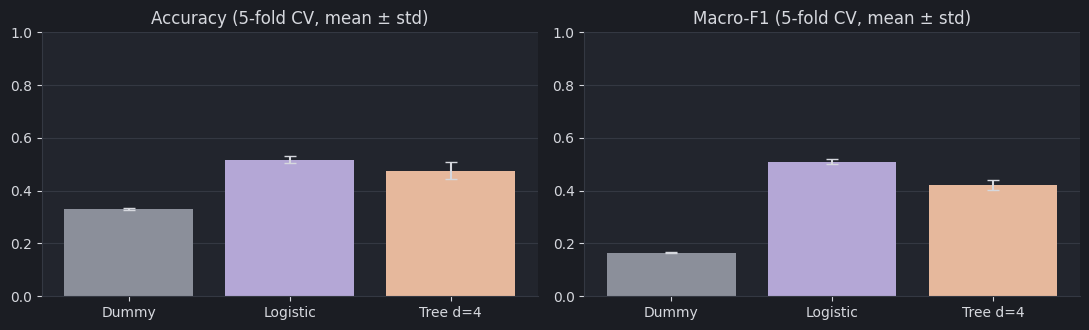

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, (m, s, title) in zip(ax, [("acc_mean", "acc_std", "Accuracy"), ("f1_mean", "f1_std", "Macro-F1")]):
    a.bar(range(len(res)), res[m], yerr=res[s], color=MODEL_COLORS, capsize=4, ecolor=TEXT)
    a.set_xticks(range(len(res)))
    a.set_xticklabels(["Dummy", "Logistic", "Tree d=4"])
    a.set_title(title + " (5-fold CV, mean ± std)")
    a.set_ylim(0, 1)
    a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 6. Where the best model goes wrong
**What this shows:** which bands get mixed up. Rows = true band, columns = predicted band (counts, 5-fold predictions).

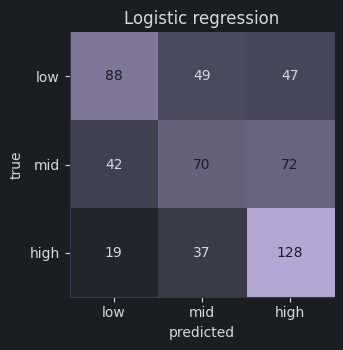

              precision    recall  f1-score   support

         low       0.59      0.48      0.53       184
         mid       0.45      0.38      0.41       184
        high       0.52      0.70      0.59       184

    accuracy                           0.52       552
   macro avg       0.52      0.52      0.51       552
weighted avg       0.52      0.52      0.51       552



In [9]:
order = ["low", "mid", "high"]
pred = cross_val_predict(make(models[best]), X, y, cv=cv)
cm = confusion_matrix(y, pred, labels=order)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("soft", [PANEL, "#b4a7d6"])
fig, a = plt.subplots(figsize=(4.2, 3.6))
a.imshow(cm, cmap=cmap)
a.set_xticks(range(3)); a.set_xticklabels(order); a.set_yticks(range(3)); a.set_yticklabels(order)
a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(best); a.grid(False)
for i in range(3):
    for j in range(3):
        a.text(j, i, cm[i, j], ha="center", va="center", color=BG if cm[i, j] > cm.max() / 2 else TEXT)
plt.tight_layout(); plt.show()
print(classification_report(y, pred, labels=order, digits=2))

## 7. Read the tree
**What this shows:** the rules of the depth-4 tree, fitted on all rows only to read them (scores above come from CV).

In [10]:
tree = make(DecisionTreeClassifier(max_depth=4, random_state=SEED)).fit(X, y)
names = list(tree[:-1].get_feature_names_out())
print(export_text(tree[-1], feature_names=names))

|--- work_type_Full-time <= 0.50
|   |--- experience_Mid-Senior level <= 0.50
|   |   |--- work_type_Internship <= 0.50
|   |   |   |--- work_type_Temporary <= 0.50
|   |   |   |   |--- class: low
|   |   |   |--- work_type_Temporary >  0.50
|   |   |   |   |--- class: high
|   |   |--- work_type_Internship >  0.50
|   |   |   |--- class: low
|   |--- experience_Mid-Senior level >  0.50
|   |   |--- remote_remote <= 0.50
|   |   |   |--- work_type_Temporary <= 0.50
|   |   |   |   |--- class: low
|   |   |   |--- work_type_Temporary >  0.50
|   |   |   |   |--- class: mid
|   |   |--- remote_remote >  0.50
|   |   |   |--- work_type_Contract <= 0.50
|   |   |   |   |--- class: mid
|   |   |   |--- work_type_Contract >  0.50
|   |   |   |   |--- class: mid
|--- work_type_Full-time >  0.50
|   |--- experience_Entry level <= 0.50
|   |   |--- experience_Associate <= 0.50
|   |   |   |--- experience_Director <= 0.50
|   |   |   |   |--- class: high
|   |   |   |--- experience_Director >  0

## 8. RESULTS
- Dummy baseline: accuracy 0.33, macro-F1 0.165. It always guesses one band, so this is the score of pure guessing. Any real model must beat it.
- Best model: logistic regression (accuracy 0.518, macro-F1 0.51). It beats the dummy by +0.345 macro-F1. The fold std is 0.009, so the gain is much bigger than the noise. The decision tree is weaker (macro-F1 0.421) and less stable (std 0.019).
- Hardest band: mid. Its recall is 0.38 and its F1 is 0.41. Of 184 mid jobs, only 70 were correct: 72 were called high and 42 low. High is the easiest band (recall 0.70).
- What the tree uses most: it splits first on full-time or not, then on experience level. Full-time Entry and Associate jobs go to low, other full-time jobs go to high. Remote is only used deeper, and two of its three splits give the same class on both sides.
- Why skill features are next: experience, work type and remote are only 3 weak fields and 552 rows, so this score is a floor. Logistic regression scores 0.531 on train and 0.51 on test, so it is not overfitting; it just lacks information. Skill flags and job-family clusters should add some. This is the next test, not proven yet.